In [ ]:
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git

2.10.0+cu128
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install -qq fvcore torchmetrics simtorch CKA

In [ ]:
# Import Libraries
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from torch_geometric.nn import GCNConv
from torch_geometric.datasets import Planetoid
import torch_geometric.transforms as T
from torch.distributions.dirichlet import Dirichlet
import torch.nn.functional as F
import seaborn as sns
import numpy as np
import random
random.seed(42)
import matplotlib.pyplot as plt
name_data = 'Citeseer' # Select dataset here
dataset = Planetoid(root= '/tmp/' + name_data, name = name_data)
dataset.transform = T.NormalizeFeatures()

In [ ]:
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')
print(50*'=')
data = dataset[0]
print(data)
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')
print(f'Is undirected: {data.is_undirected()}')

Number of graphs: 1
Number of features: 3703
Number of classes: 6
Data(x=[3327, 3703], edge_index=[2, 9104], y=[3327], train_mask=[3327], val_mask=[3327], test_mask=[3327])
Number of nodes: 3327
Number of edges: 9104
Number of training nodes: 120
Training node label rate: 0.04
Is undirected: True


# Training

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv

# --- Updated GAT with embeddings extraction ---
class GAT(nn.Module):
    def __init__(self, in_features, hidden_size, num_classes, num_heads=1, dropout=0.6):
        super(GAT, self).__init__()
        self.dropout = dropout
        self.conv1 = GATConv(in_features, hidden_size, heads=num_heads, dropout=dropout)
        self.conv2 = GATConv(hidden_size * num_heads, num_classes, heads=1, concat=False, dropout=dropout)

    def forward(self, x, edge_index, return_embeddings=False):
        """
        Args:
            x: Node features [num_nodes, in_features]
            edge_index: Edge indices
            return_embeddings: If True, returns hidden embeddings from last hidden layer
        """
        x = F.dropout(x, p=self.dropout, training=self.training)
        hidden = F.elu(self.conv1(x, edge_index))  # hidden embeddings
        x = F.dropout(hidden, p=self.dropout, training=self.training)
        out = self.conv2(x, edge_index)            # logits
        if return_embeddings:
            return hidden
        return F.log_softmax(out, dim=1)

    # Convenience method for embeddings
    def get_embeddings(self, x, edge_index):
        self.eval()  # optional: keep model in eval mode for embeddings
        with torch.no_grad():
            return self.forward(x, edge_index, return_embeddings=True)

In [ ]:
class GAT1(nn.Module):
    def __init__(self, in_features, hidden_size, num_classes, num_heads=1, dropout=0.6):
        super(GAT1, self).__init__()
        self.conv1 = GATConv(in_features, hidden_size, heads=num_heads, dropout=dropout)
        self.conv2 = GATConv(hidden_size * num_heads, hidden_size, heads=num_heads, dropout=dropout)
        self.conv3 = GATConv(hidden_size * num_heads, num_classes, heads=1, concat=False, dropout=dropout)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = self.conv2(x, edge_index)
        x = F.elu(x)
        x = self.conv3(x, edge_index)
        return F.log_softmax(x, dim=1)

import torch
import torch.nn as nn
import torch.nn.functional as F

class MLP(torch.nn.Module):
    def __init__(self, in_dim, hidden_dim=512, out_dim=2, dropout=0.5):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, data):
        x = data.x  # Only node features, no edge_index used

        x = self.fc1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.fc2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.fc3(x)

        return x

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import TransformerConv

class GraphTransformer(nn.Module):
    def __init__(self, in_dim, hidden_dim=512, out_dim=2, heads=4, dropout=0.5):
        super().__init__()

        # Transformer layers
        self.conv1 = TransformerConv(in_dim, hidden_dim, heads=heads, dropout=0.1)
        self.bn1 = nn.BatchNorm1d(hidden_dim * heads)

        self.conv2 = TransformerConv(hidden_dim * heads, hidden_dim, heads=heads, dropout=0.1)
        self.bn2 = nn.BatchNorm1d(hidden_dim * heads)

        self.conv3 = TransformerConv(hidden_dim * heads, out_dim, heads=1, dropout=0.1)

        self.dropout = dropout

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv3(x, edge_index)

        return x

In [ ]:
# inspired by
# https://github.com/yuanli2333/CKA-Centered-Kernel-Alignment/blob/master/CKA.py

import math
import torch
import numpy as np

class CKA(object):
    def __init__(self):
        pass

    def centering(self, K):
        n = K.shape[0]
        unit = np.ones([n, n])
        I = np.eye(n)
        H = I - unit / n
        return np.dot(np.dot(H, K), H)

    def rbf(self, X, sigma=None):
        GX = np.dot(X, X.T)
        KX = np.diag(GX) - GX + (np.diag(GX) - GX).T
        if sigma is None:
            mdist = np.median(KX[KX != 0])
            sigma = math.sqrt(mdist)
        KX *= - 0.5 / (sigma * sigma)
        KX = np.exp(KX)
        return KX

    def kernel_HSIC(self, X, Y, sigma):
        return np.sum(self.centering(self.rbf(X, sigma)) * self.centering(self.rbf(Y, sigma)))

    def linear_HSIC(self, X, Y):
        L_X = X @ X.T
        L_Y = Y @ Y.T
        return np.sum(self.centering(L_X) * self.centering(L_Y))

    def linear_CKA(self, X, Y):
        hsic = self.linear_HSIC(X, Y)
        var1 = np.sqrt(self.linear_HSIC(X, X))
        var2 = np.sqrt(self.linear_HSIC(Y, Y))

        return hsic / (var1 * var2)

    def kernel_CKA(self, X, Y, sigma=None):
        hsic = self.kernel_HSIC(X, Y, sigma)
        var1 = np.sqrt(self.kernel_HSIC(X, X, sigma))
        var2 = np.sqrt(self.kernel_HSIC(Y, Y, sigma))

        return hsic / (var1 * var2)


class CudaCKA(object):
    def __init__(self, device):
        self.device = device

    def centering(self, K):
        n = K.shape[0]
        unit = torch.ones([n, n], device=self.device)
        I = torch.eye(n, device=self.device)
        H = I - unit / n
        return torch.matmul(torch.matmul(H, K), H)

    def rbf(self, X, sigma=None):
        GX = torch.matmul(X, X.T)
        KX = torch.diag(GX) - GX + (torch.diag(GX) - GX).T
        if sigma is None:
            mdist = torch.median(KX[KX != 0])
            sigma = math.sqrt(mdist)
        KX *= - 0.5 / (sigma * sigma)
        KX = torch.exp(KX)
        return KX

    def kernel_HSIC(self, X, Y, sigma):
        return torch.sum(self.centering(self.rbf(X, sigma)) * self.centering(self.rbf(Y, sigma)))

    def linear_HSIC(self, X, Y):
        L_X = torch.matmul(X, X.T)
        L_Y = torch.matmul(Y, Y.T)
        return torch.sum(self.centering(L_X) * self.centering(L_Y))

    def linear_CKA(self, X, Y):
        hsic = self.linear_HSIC(X, Y)
        var1 = torch.sqrt(self.linear_HSIC(X, X))
        var2 = torch.sqrt(self.linear_HSIC(Y, Y))

        return hsic / (var1 * var2)

    def kernel_CKA(self, X, Y, sigma=None):
        hsic = self.kernel_HSIC(X, Y, sigma)
        var1 = torch.sqrt(self.kernel_HSIC(X, X, sigma))
        var2 = torch.sqrt(self.kernel_HSIC(Y, Y, sigma))
        return hsic / (var1 * var2)

Epoch 000, Loss: 1.7917
Epoch 100, Loss: 0.6630
Epoch 200, Loss: 0.6778
Epoch 300, Loss: 0.5987
Epoch 400, Loss: 0.6461


Epoch 500, Loss: 0.6743
Total Training Time: 8.10s
Test Accuracy: 0.6770
F1 Score: 0.6493, Precision: 0.6634, Recall: 0.6607
Estimated FLOPs: 6,317,999,616
Expected Calibration Error (ECE): 0.2154
CKA Similarity: 1.0000


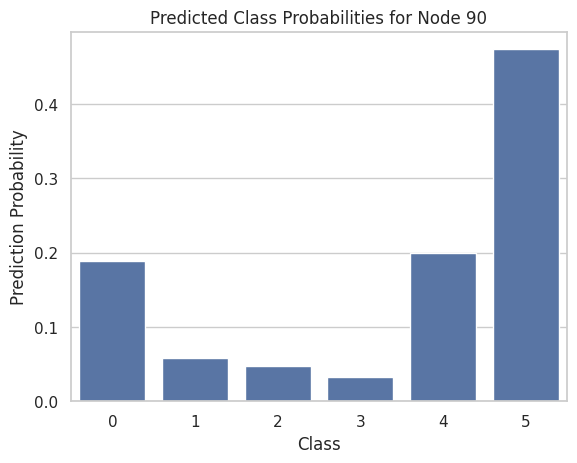

In [ ]:
import torch
import torch.nn.functional as F
import time
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score
from torchmetrics.classification import CalibrationError
from fvcore.nn import FlopCountAnalysis
import warnings
warnings.filterwarnings("ignore")

# --- Initialize model ---
model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.5)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)
data = data.to(device)

# --- Optimizer & Loss ---
learning_rate = 0.01
weight_decay = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
criterion = torch.nn.CrossEntropyLoss()

# --- Training function ---
def train():
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

# --- Testing function ---
def test():
    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        test_mask = data.test_mask
        test_acc = (pred[test_mask] == data.y[test_mask]).sum().item() / test_mask.sum().item()
    return test_acc, pred

# --- Training loop with timing ---
start_time = time.time()
losses = []

for epoch in range(501):
    loss = train()
    losses.append(loss)
    if epoch % 100 == 0:
        print(f'Epoch {epoch:03d}, Loss: {loss:.4f}')

end_time = time.time()
execution_time = end_time - start_time
print(f"Total Training Time: {execution_time:.2f}s")

# --- Evaluate ---
test_acc, pred = test()
print(f"Test Accuracy: {test_acc:.4f}")

# --- Metrics: F1, Precision, Recall ---
y_true = data.y[data.test_mask].cpu().numpy()
y_pred = pred[data.test_mask].cpu().numpy()
f1 = f1_score(y_true, y_pred, average='macro')
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
print(f"F1 Score: {f1:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}")

# --- FLOPs calculation ---
flops = FlopCountAnalysis(model, (data.x, data.edge_index))
print(f"Estimated FLOPs: {flops.total():,}")

# --- Calibration Error (ECE) ---
calibration_error = CalibrationError(task="multiclass", num_classes=dataset.num_classes).to(device)
ece = calibration_error(model(data.x, data.edge_index), data.y)
print(f"Expected Calibration Error (ECE): {ece.item():.4f}")

# --- CKA Similarity ---
# You need a second embedding set; here we use the same model as a "teacher" for demonstration  # make sure CudaCKA is imported
with torch.no_grad():
    emb_student = model.get_embeddings(data.x, data.edge_index)
    emb_teacher = model.get_embeddings(data.x, data.edge_index)  # could be a separate pretrained model
    emb_student = emb_student.to(device)
    emb_teacher = emb_teacher.to(device)
    cuda_cka = CudaCKA(device)
    cka_score = cuda_cka.linear_CKA(emb_student, emb_teacher)
print(f"CKA Similarity: {cka_score:.4f}")

# --- Visualization for a sample node ---
sample_idx = 90
sns.set_theme(style="whitegrid")
pred_probs = F.softmax(model(data.x, data.edge_index), dim=-1)[sample_idx].detach().cpu().numpy()
sns.barplot(x=np.arange(dataset.num_classes), y=pred_probs)
plt.xlabel("Class")
plt.ylabel("Prediction Probability")
plt.title(f"Predicted Class Probabilities for Node {sample_idx}")
plt.savefig("class_t.png", dpi=300)
plt.show()

## Training of the distilled student model using DMSD

In [ ]:
from torch_geometric.datasets import Planetoid
from torch_geometric.loader import LinkNeighborLoader
name_data = 'Citeseer' # Select dataset here
dataset = Planetoid(root= '/tmp/' + name_data, name = name_data)
dataset.transform = T.NormalizeFeatures()
data = dataset[0]

loader = LinkNeighborLoader(
    data,
    num_neighbors=[100] * 10,
    batch_size=512,
    edge_label_index=data.edge_index,
)
sampled_data = next(iter(loader))

# Divergent Memory

In [ ]:
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import f1_score

Test accuracy last 0.39774330042313116
Test accuracy last 0.3159379407616361
Total Training + Evaluation Time: 0.26s
Estimated FLOPs: 4,481,658,880
Test Accuracy: 0.3159
F1 Score: 0.1768, Precision: 0.5019, Recall: 0.2485
CKA Similarity: 0.8851
Expected Calibration Error (ECE): 0.1717


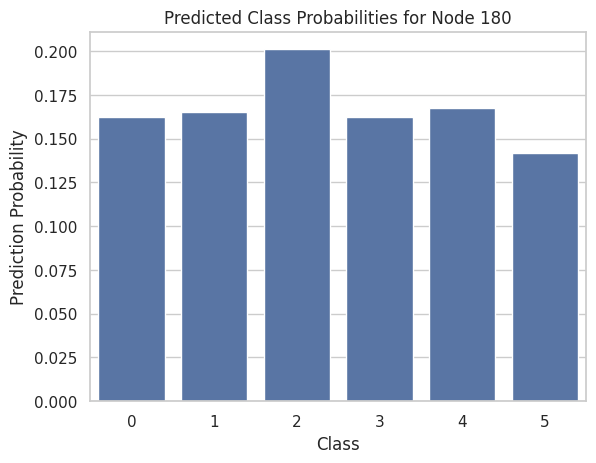

In [ ]:
import torch
import torch.nn.functional as F
import os
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import time
from sklearn.metrics import f1_score, precision_score, recall_score
from torchmetrics.classification import CalibrationError
from fvcore.nn import FlopCountAnalysis
import warnings
warnings.filterwarnings("ignore")
# --- Monte Carlo Dropout Uncertainty ---
def mc_dropout_uncertainty(model, x, edge_index, T=10):
    model.train()  # keep dropout active
    preds = []
    for t in range(T):
        logits = model(x, edge_index)
        probs = F.softmax(logits, dim=-1)
        preds.append(probs.unsqueeze(0))
    preds = torch.cat(preds, dim=0)       # [T, N, C]
    variance = preds.var(dim=0)           # [N, C]
    uncertainty = variance.mean(dim=1)    # [N]
    uncertainty = uncertainty / uncertainty.max()  # normalize to [0,1]
    return uncertainty

# --- Initialize Models ---
s_model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.5)
m_model = GAT(dataset.num_features, hidden_size=64, num_classes=dataset.num_classes, num_heads=8, dropout=0.5)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)
s_model = s_model.to(device)
m_model = m_model.to(device)
data = sampled_data.to(device)

# --- Optimizer & Losses ---
learning_rate = 0.01
decay = 7e-4
s_optimizer = torch.optim.Adam(s_model.parameters(), lr=learning_rate, weight_decay=decay)
criterion_ce = torch.nn.NLLLoss()
criterion_kd = torch.nn.MSELoss()

alpha, beta, gamma = 1.0, 0.005, 0.55
temperature = 10
best_acc = 0
losses_1 = []

# --- Timing ---
start_time = time.time()

# --- KD Training Loop with Monte Carlo Dropout ---
for epoch in range(0, 2):
    model.eval()
    if os.path.exists('memory.pth'):
      model.load_state_dict(torch.load('memory.pth'))  # load teacher weights
    s_model.train()
    s_optimizer.zero_grad()

    student_logits = s_model(data.x, data.edge_index)

    with torch.no_grad():
        teacher_logits = model(data.x, data.edge_index)

    instance_weight = mc_dropout_uncertainty(s_model, data.x, data.edge_index, T=10)

    student_probs = F.softmax(student_logits / temperature, dim=-1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=-1)

    if os.path.exists('memory_div.pth'):
        m_model.eval()
        m_model.load_state_dict(torch.load('memory_div.pth'))
        student_logits_mem = m_model(data.x, data.edge_index)
        student_probs_mem = F.softmax(student_logits_mem / temperature, dim=-1)
    else:
        student_probs_mem = student_probs

    batch_loss1 = F.kl_div(student_probs, teacher_probs, reduction="none").sum(-1) / (temperature ** 2)
    batch_loss2 = F.kl_div(student_probs_mem, teacher_probs, reduction="none").sum(-1) / (temperature ** 2)
    loss_kd = torch.mean(batch_loss1 * instance_weight) + torch.mean(batch_loss2 * instance_weight)

    loss_sim = criterion_kd(F.softmax(teacher_logits[data.train_mask] / temperature, dim=-1),
                            F.softmax(student_logits[data.train_mask] / temperature, dim=-1))
    loss_ce = criterion_ce(student_logits[data.train_mask], data.y[data.train_mask])
    loss_div = F.kl_div(student_probs_mem, student_probs, reduction="none").sum(-1) / (temperature ** 2)

    loss = alpha * loss_ce + beta * loss_sim + gamma * loss_kd
    loss.backward()
    s_optimizer.step()
    losses_1.append(loss.item())

    if epoch > 0 and loss_div[epoch-1] < loss_div[epoch]:
        torch.save(s_model.state_dict(), 'memory_div.pth')

    s_model.eval()
    pred = s_model(data.x, data.edge_index).argmax(dim=1)
    test_correct = pred[data.test_mask] == data.y[data.test_mask]
    test_acc = int(test_correct.sum()) / int(data.test_mask.sum())
    last_acc =test_acc
    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(s_model.state_dict(), 's_div.pth')
    print("Test accuracy last", last_acc)

# --- End Timing ---
end_time = time.time()
execution_time = end_time - start_time
print(f"Total Training + Evaluation Time: {execution_time:.2f}s")

# --- FLOPs Calculation ---
flops = FlopCountAnalysis(s_model, (data.x, data.edge_index))
print(f"Estimated FLOPs: {flops.total():,}")
# --- Accuracy ---
logits = s_model(data.x, data.edge_index)        # [num_nodes, num_classes]
pred_classes = logits.argmax(dim=1)             # predicted labels
labels = data.y                                 # true labels

test_mask = data.test_mask
accu = (pred_classes[test_mask] == labels[test_mask]).sum().item() / test_mask.sum().item()
print(f"Test Accuracy: {accu:.4f}")
# --- Metrics ---
from sklearn.metrics import f1_score, precision_score, recall_score

pred_classes = s_model(data.x, data.edge_index).argmax(dim=1)
y_true = data.y[data.test_mask].cpu().numpy()
y_pred = pred_classes[data.test_mask].cpu().numpy()

f1 = f1_score(y_true, y_pred, average='macro')
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
print(f"F1 Score: {f1:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}")


device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

with torch.no_grad():
    # Get embeddings
    emb_student = s_model.get_embeddings(data.x, data.edge_index)  # [num_nodes, hidden_size*num_heads]
    emb_teacher = model.get_embeddings(data.x, data.edge_index)    # teacher embeddings

    # Move to device
    emb_student = emb_student.to(device)
    emb_teacher = emb_teacher.to(device)

    # Compute CKA similarity on GPU
    cuda_cka = CudaCKA(device)
    cka_score = cuda_cka.linear_CKA(emb_student, emb_teacher)

print(f"CKA Similarity: {cka_score:.4f}")

# --- Expected Calibration Error ---
calibration_error = CalibrationError(task="multiclass",num_classes=6).to(device)
ece = calibration_error(s_model(data.x, data.edge_index), data.y)
print(f"Expected Calibration Error (ECE): {ece.item():.4f}")

# --- Visualization for a sample node with MC Dropout ---
sample_idx = 180
y_vals = F.softmax(s_model(data.x, data.edge_index), dim=-1)[sample_idx].detach().cpu().numpy()
x_vals = np.arange(dataset.num_classes)

sns.set_theme(style="whitegrid")
sns.barplot(x=x_vals, y=y_vals)
plt.xlabel("Class")
plt.ylabel("Prediction Probability")
plt.title(f"Predicted Class Probabilities for Node {sample_idx}")
plt.savefig("class_nsb_mc_dropout_metrics.png", dpi=300)
plt.show()